# Carrier-phase DD AoA experiment

Edit the two UBX paths and the spoof group below, then **Run All**.
The flow is **inputs → data and rig checks → DD calculation per spoof-group window → results**.
A long capture can hold several windows (for example before and after a receiver cold start); each one is solved and saved separately.
The experiment saves its analysis tables; publication figure export is in [AOA_Export_Figures.ipynb](AOA_Export_Figures.ipynb).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

from aoa_experiment import ExperimentConfig, check_experiment, run_experiment_windows, result_table, angle_reference_summary
from aoa_pipeline import (
    plot_aoa_tracks, plot_spoof_branch_summary, plot_fractional_dd,
    navsat_sv_status_by_second, summarize_sv_used_by_window, plot_sv_used_by_tow,
)

## 1. Inputs

RX1 and RX2 mean the antennas connected to the two UBX files; COM/USB order does not identify north or south. In this model, `rx1-rx2` uses the directed RX1 → RX2 baseline; `rx2-rx1` uses RX2 → RX1. Its assumed azimuth is clockwise from north: 0° = north, 180° = south.

`angle_reference` controls the reporting direction:
- `"configured"`: use the subtraction order and baseline azimuth below.
- `"opposite"`: reverse both consistently and report the complementary angle.
- `"closest_to_expected"`: choose between those two equivalent references using `expected_aoa_deg`.

An approximate expectation with an unknown reference direction is a **reporting preference**, not a wiring calibration. This option preserves the measured angles and the integer-branch ambiguity. Keep `prior_aoa_deg=None` unless an independently justified branch prior is available.

In [2]:
CONFIG = ExperimentConfig(
    name='sp-partial-28-09/v2-prior90',
    receiver1_path=Path('dataset/sp-partial-28-09/90/COM3___9600_260928_103310.ubx'),
    receiver2_path=Path('dataset/sp-partial-28-09/90/COM4___9600_260928_103302.ubx'),
    spoof_svids=(10, 23, 28, 32),
    single_difference_order='rx2-rx1',
    baseline_azimuth_deg=0.0,
    baseline_over_wavelength=1.0,
    reference_svid=None,
    spoof_branch_m=None,
    prior_aoa_deg=90.0,
    angle_reference='configured',
    min_window_epochs=5,
)

## 2. Check the capture

Carrier phase must be valid in both receivers, and both receivers need a NAV-PVT fix: without one (e.g. during a cold start) NAV-PVT reports `nano = 0`, the Eq. 8 time correction is unavailable, and those epochs are dropouts. Every window where the spoof group is tracked is listed below; windows with at least `min_window_epochs` valid epochs are solved. The rig check compares authentic-satellite phase differences with the configured geometry.

In [3]:
checks = check_experiment(CONFIG)
print(f"Synchronized epochs: {len(checks.probe.synced.epochs)}")
display(checks.probe.spoof_phase_summary[
    ["svid", "common_valid_epochs", "longest_common_run", "usable"]
])
print("Spoof-group windows:")
display(checks.probe.spoof_windows)
for warning in checks.probe.warnings:
    print("Warning:", warning)
print("Rig check:", checks.rig.recommendation)

Synchronized epochs: 285


,svid,common_valid_epochs,longest_common_run,usable
0,10,265,136,True
1,23,265,136,True
2,28,265,136,True
3,32,265,136,True


Spoof-group windows:


,window,start_epoch,end_epoch,epochs,valid_epochs,start_tow,end_tow,solvable
0,1,0,135,136,136,124414.004,124549.004,True
1,2,150,278,129,129,124596.000,124724.004,True


Rig check: configured baseline azimuth 0 deg is consistent with the authentic PRNs (fit 357 deg, median residual 0.042 cycles at the fit, 0.043 as configured).


## 3. Run the DD method

The pipeline corrects carrier phase, forms receiver and satellite differences, wraps the DD into fractional cycles, and computes the valid integer-branch AoAs. Spoof PRNs are solved jointly as a candidate common source.
Each window is an independent experiment (its own reference satellite, reference-angle anchor and branch decision; nothing is carried across a reacquisition), saved under `window_NN/` in the output folder. `windows.csv` lists every window, including skipped or failed ones.

In [4]:
windows = run_experiment_windows(CONFIG, checks)
print(f"Analysis tables: {CONFIG.output_dir}")
display(windows.summary.drop(columns=["output_dir"], errors="ignore").round(2))

Analysis tables: /Users/betty/Developer/research/angle/outputs/aoa_experiments/sp-partial-28-09/v2-prior90


,window,start_tow,end_tow,capture_epochs,valid_epochs,status,note,epochs,reference_svid,group_aoa_deg,group_spread_deg,other_branch_deg,chosen_by,flagged_all_branches,selected_reference
0,1,124414.0,124549.0,0-135,136,solved,,136,9,94.81,0.16,23.71,prior,3,configured
1,2,124597.0,124724.0,151-278,129,solved,,128,9,93.64,0.16,18.78,prior,3,configured


## 4. Results

Per window, the reported reference and effective subtraction order are printed explicitly. `closest_to_expected` also audits both physical wiring hypotheses; it does not select a wiring hypothesis from the target angle. Lower authentic-satellite residual supports a hypothesis but does not establish the physical antenna labels.

The table retains the alternate integer branch. Missing geometry remains unavailable, while valid DD measurements are retained.

In [5]:
print("Physical receiver orientation remains unconfirmed.")
for window, scenario in windows.scenarios.items():
    reference = angle_reference_summary(windows.configs[window], scenario)
    epochs = scenario.analysis_result.epochs["rcvTow_rx1"]
    print(f"\nWindow {window}: TOW {epochs.iloc[0]:.0f}-{epochs.iloc[-1]:.0f} ({len(epochs)} epochs), reference PRN {scenario.analysis_result.reference_svid}")
    print(f"  Reported spoof-group AoA: {reference['reported_aoa_deg']:.2f}°; other directed reference: {reference['other_reference_aoa_deg']:.2f}°")
    print(f"  Reference: {reference['selected_reference']}; selected by {reference['selected_by']}; "
          f"effective order {reference['effective_single_difference_order']}, assumed baseline azimuth {reference['effective_baseline_azimuth_deg']:.0f}°")
    print("  Branch selection:", ", ".join(sorted(set(scenario.joint_source_ambiguity.chosen_by))))
    display(result_table(scenario).round(2))
    if not windows.orientation_hypotheses[window].empty:
        print(f"Wiring audit: configured axis = {CONFIG.baseline_azimuth_deg:g}°; opposite axis = {(CONFIG.baseline_azimuth_deg + 180) % 360:g}°")
        display(windows.orientation_hypotheses[window].round(3))

Physical receiver orientation remains unconfirmed.

Window 1: TOW 124414-124549 (136 epochs), reference PRN 9
  Reported spoof-group AoA: 94.81°; other directed reference: 85.19°
  Reference: configured; selected by explicit_reference; effective order rx2-rx1, assumed baseline azimuth 0°
  Branch selection: prior


,PRN,DD AoA (deg),Std (deg),Other branch (deg),Ephemeris (deg),DD epochs,Geometry epochs,Branch selection,Flag on all branches
0,10,94.85,0.59,23.78,128.34,135,126,prior,True
1,23,94.87,0.61,23.78,94.37,135,132,prior,False
2,28,94.81,0.61,23.64,54.63,134,132,prior,True
3,32,94.80,0.62,23.60,62.31,135,126,prior,True



Window 2: TOW 124597-124724 (128 epochs), reference PRN 9
  Reported spoof-group AoA: 93.64°; other directed reference: 86.36°
  Reference: configured; selected by explicit_reference; effective order rx2-rx1, assumed baseline azimuth 0°
  Branch selection: prior


,PRN,DD AoA (deg),Std (deg),Other branch (deg),Ephemeris (deg),DD epochs,Geometry epochs,Branch selection,Flag on all branches
0,10,92.35,34.69,18.75,128.34,128,115,prior,True
1,23,92.32,34.68,18.83,94.37,128,115,prior,False
2,28,92.46,34.66,18.65,54.63,128,115,prior,True
3,32,92.40,34.69,18.82,62.31,128,115,prior,True


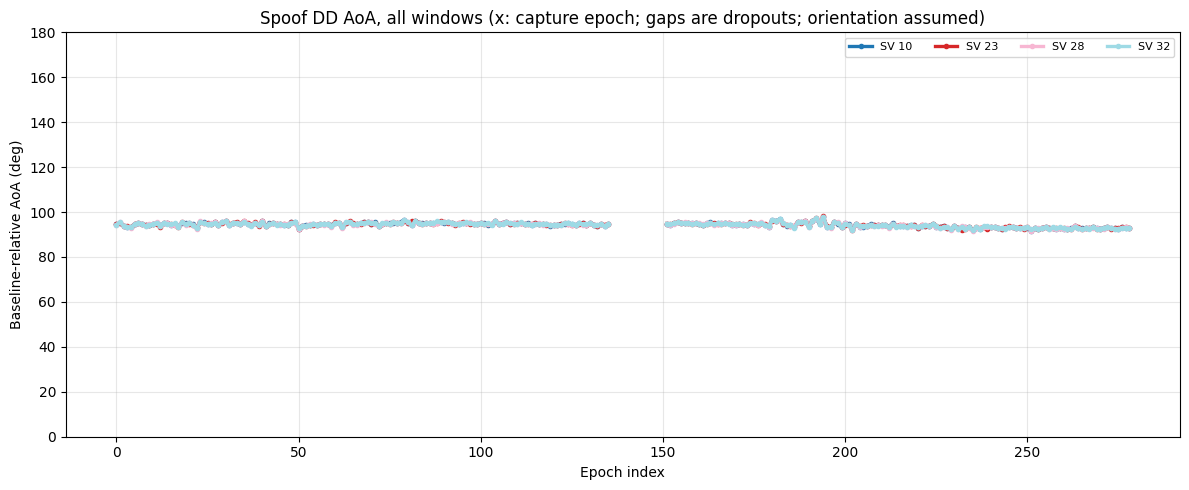

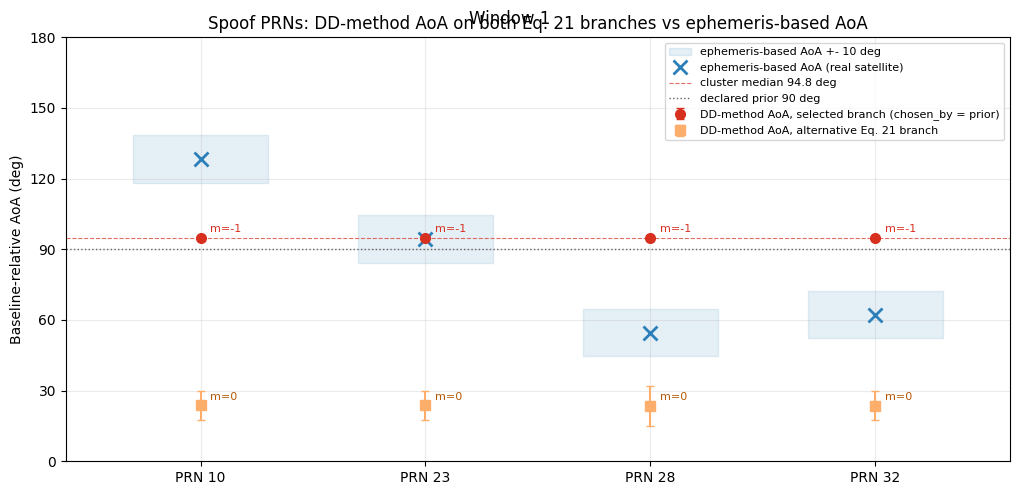

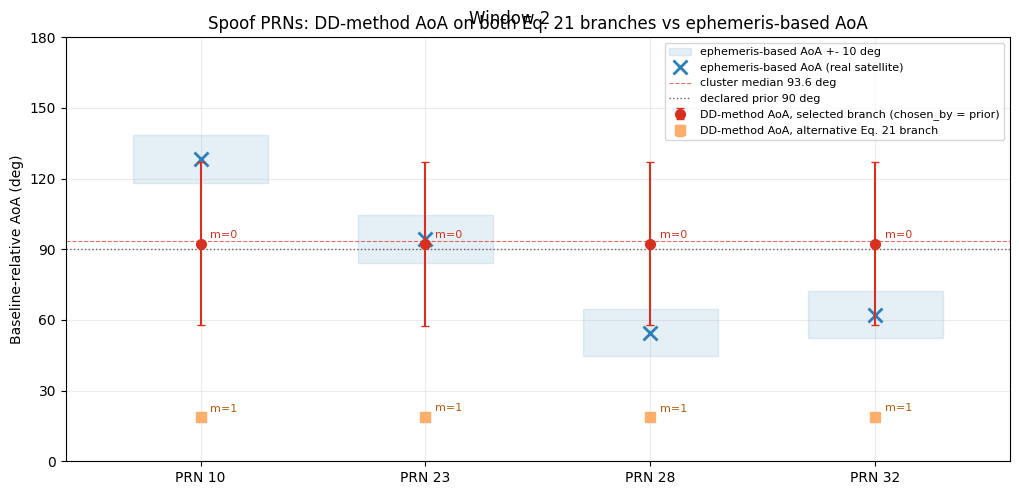

In [6]:
fig = plot_aoa_tracks(
    windows.aoa_by_capture_epoch(),
    title="Spoof DD AoA, all windows (x: capture epoch; gaps are dropouts; orientation assumed)",
    highlight_svids=checks.probe.usable_spoof_svids,
)
display(fig)
plt.close(fig)

for window, scenario in windows.scenarios.items():
    fig = plot_spoof_branch_summary(
        scenario.spoof_branch_detection,
        prior_aoa_deg=scenario.prior_aoa_deg,
        cluster_median_aoa_deg=float(scenario.joint_source_aoa_deg.median(axis=1).median()),
    )
    fig.suptitle(f"Window {window}")
    display(fig)
    plt.close(fig)

### Are the spoof PRNs used in the receiver's fix?

NAV-SAT `svUsed` shows whether each receiver's own PVT solution used a PRN. The table gives the percentage of each window's seconds in which the PRN was used (NAV-SAT dropouts count as not used); authentic PRNs are listed when used at some point. In the figure, spoof PRNs are above the red line, dashed lines mark the windows, and the bottom panel counts used spoof and authentic PRNs per receiver. Saved as `sv_used_by_window.csv`.

window              1             2       
receiver          RX1    RX2    RX1    RX2
role      svid                            
spoof     32     93.0   93.0   91.0   91.0
          28     98.0   93.0   91.0   91.0
          23     98.0   93.0   91.0   91.0
          10     93.0   93.0   91.0   91.0
authentic 31      1.0   74.0    NaN   52.0
          27    100.0  100.0   91.0  100.0
          26      NaN    NaN    NaN   72.0
          16    100.0  100.0  100.0  100.0
          9     100.0  100.0  100.0  100.0
          8     100.0  100.0  100.0  100.0
          7     100.0  100.0  100.0   98.0
          4     100.0  100.0  100.0  100.0
          3       NaN   13.0    NaN    NaN
          2       NaN  100.0    NaN    NaN

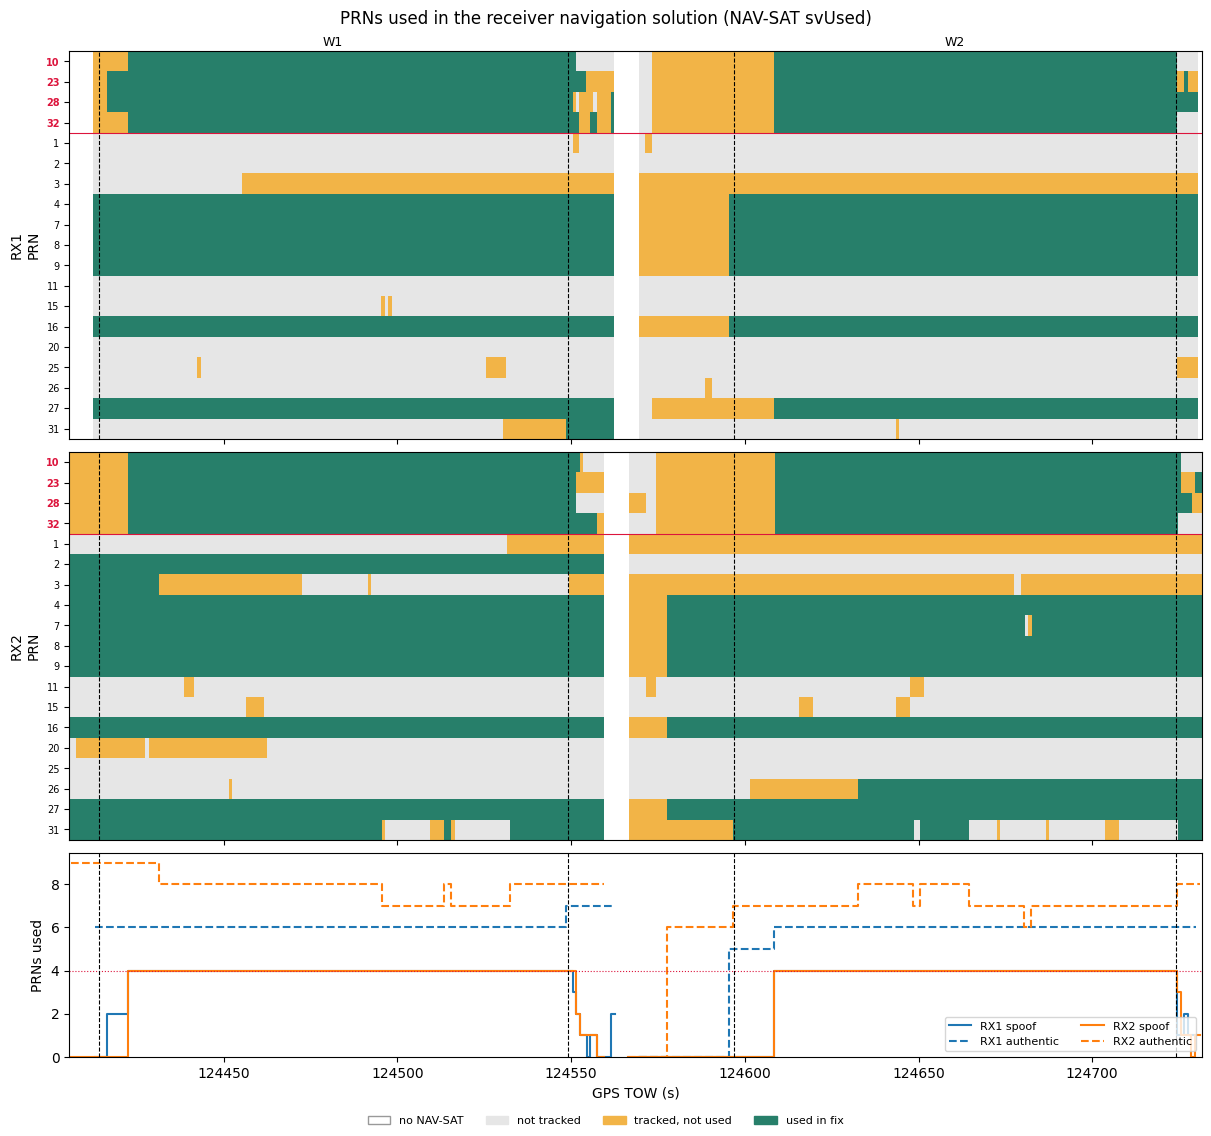

In [7]:
sv_status = {
    "RX1": navsat_sv_status_by_second(checks.probe.observations[0].navsat),
    "RX2": navsat_sv_status_by_second(checks.probe.observations[1].navsat),
}
sv_used = summarize_sv_used_by_window(sv_status, windows.summary, CONFIG.spoof_svids)
sv_used.to_csv(CONFIG.output_dir / "sv_used_by_window.csv", index=False)
shown = sv_used[sv_used.role.eq("spoof") | sv_used.used_seconds.gt(0)]  # the CSV keeps every tracked PRN
display(
    shown.pivot_table(index=["role", "svid"], columns=["window", "receiver"], values="pct_used")
    .sort_index(level=0, ascending=False).round(0)
)
fig = plot_sv_used_by_tow(sv_status, highlight_svids=CONFIG.spoof_svids, windows=windows.summary)
display(fig)
plt.close(fig)

## 5. Optional diagnostics

Enable the cell below to inspect, per window, fractional DD, the analysis window, and authentic-satellite angle errors, plus the capture-wide common-source phase agreement. All intermediate tables are already saved.

In [8]:
SHOW_DIAGNOSTICS = False

if SHOW_DIAGNOSTICS:
    display(checks.phase_collapse.round(4))
    for window, scenario in windows.scenarios.items():
        print(f"Window {window}")
        display(scenario.window_quality)
        agreement = scenario.aoa_method_equivalence_summary
        display(agreement.loc[
            agreement.method.eq("ephemeris_aligned_per_epoch_m")
            & ~agreement.svid.isin(CONFIG.spoof_svids)
        ].round(2))
        fig = plot_fractional_dd(scenario.all_satellite_result, highlight_svids=scenario.spoof_svids)
        display(fig)
        plt.close(fig)

Each window's `window_NN/experiment.json` records the exact inputs (including its epoch range), geometry, branch settings, and source hashes. Open [AOA_Export_Figures.ipynb](AOA_Export_Figures.ipynb) and point `EXPERIMENT_FILE` at the window you want for its complete figure set.